# # MINE-4101: Ciencia de Datos Aplicada — Taller 2
# **Caso de Negocio:** Predicción de Churn para Campañas de Retención en FinAlpes  
# **Objetivo:** Análisis exploratorio, modelamiento predictivo, interpretabilidad y estimación de valor económico.

In [1]:
# 1. Importación de librerías esenciales
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, f1_score, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
# 2. Carga robusta de datos (Local con fallback a URL remota)
LOCAL_PATH = Path("../data/raw/churn.csv")
REMOTE_URL = "https://datascience-uniandes.github.io/PracticasMachineLearning/datos/churn.csv"

if LOCAL_PATH.exists():
    df = pd.read_csv(LOCAL_PATH)
    print(f"Dataset cargado localmente desde: {LOCAL_PATH}")
else:
    df = pd.read_csv(REMOTE_URL)
    print(f"Dataset cargado desde repositorio remoto: {REMOTE_URL}")

print(f"Dimensiones del dataset: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Dataset cargado localmente desde: ..\data\raw\churn.csv
Dimensiones del dataset: 10045 filas, 11 columnas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  object 
 2   gender            10045 non-null  object 
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 863.4+ KB


Eso me indica que hay algunos datos de algunas filas nulos pues no todos tienen 10045 datos

In [4]:
df.describe(include="object")

,country,gender
count,10045,10045
unique,9,4
top,France,Male
freq,5003,5464


De las 2 variables categoricas la columna de country solo tiene 9 ciudades unicas y la de genero, 4 generos diferentes. Tal vez sirva revisar la distribucion de cada uno despues.

In [5]:
df.describe() 

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9795.000000,9745.000000,10045.000000,9845.000000,10045.000000,10045.000000,10045.000000,9695.000000,10045.000000
mean,650.690148,38.937609,5.018915,76317.500287,1.530114,0.704530,0.514684,100069.014751,0.203584
std,97.087963,10.734222,2.901585,62422.434819,0.581829,0.456277,0.499809,57510.689111,0.402683
min,95.000000,-1.000000,-2.000000,0.000000,1.000000,0.000000,0.000000,-5000.000000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,51013.655000,0.000000
50%,652.000000,37.000000,5.000000,97042.600000,1.000000,1.000000,1.000000,100130.950000,0.000000
75%,718.000000,44.000000,8.000000,127559.970000,2.000000,1.000000,1.000000,149382.875000,0.000000
max,1200.000000,210.000000,25.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


Hay varios problemas en columnas que tendre que tratar, cosas como edades negativas, salario negativo (que podria ser algo de deudas activas pero despues vere si es asi). Por ahora me interesa ver la cantidad de datos de churn positivos y negativos.

In [6]:
# Gráfica directa de la variable objetivo
ax = sns.countplot(data=df, x="churn", palette=["#2b5c8f", "#d9534f"])
ax.set_title("Distribución de Clientes: Churn vs No Churn")
ax.set_xticklabels(["Retenido (0)", "Desertó (1)"])
plt.show()

# Resumen de conteo y porcentaje
resumen_churn = pd.concat([
    df["churn"].value_counts().rename("Cantidad"),
    df["churn"].value_counts(normalize=True).mul(100).round(2).rename("Porcentaje (%)")
], axis=1)

resumen_churn.index = ["Retenido (0)", "Desertó (1)"]
display(resumen_churn)

C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\184298138.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="churn", palette=["#2b5c8f", "#d9534f"])
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\184298138.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Retenido (0)", "Desertó (1)"])


<Figure size 640x480 with 1 Axes>

,Cantidad,Porcentaje (%)
Retenido (0),8000,79.64
Desertó (1),2045,20.36


Viendo esta distribucion se que esta bastante desbalanceada, casi el 80% pertenecen a una sola clase.

C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\198104741.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Blues_r')
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\198104741.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Blues_r')
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\198104741.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Blues_r')
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\198104741.p

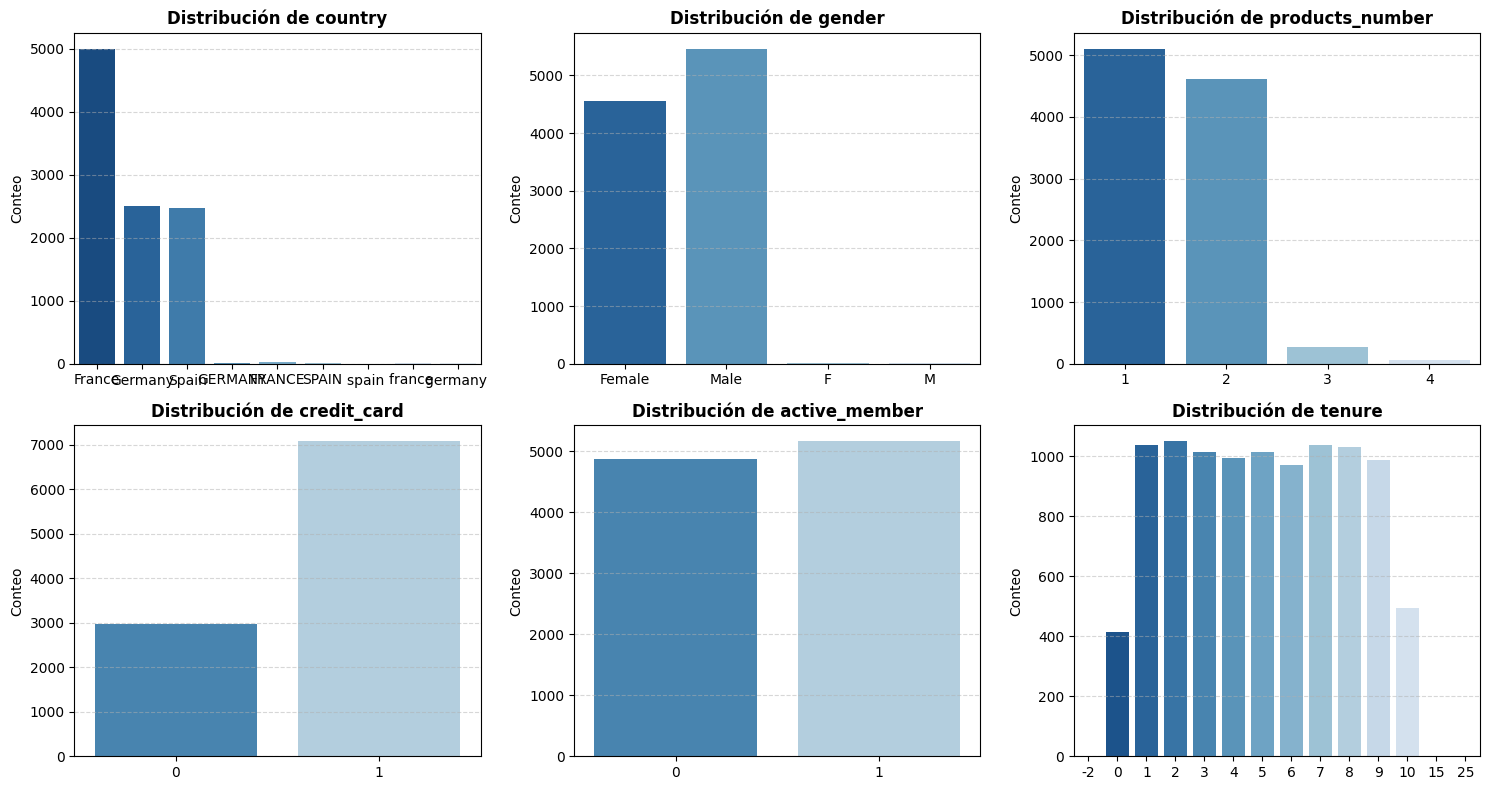

In [7]:
cols_categoricas = ['country', 'gender', 'products_number', 'credit_card', 'active_member', 'tenure']

n_cols = 3
n_rows = math.ceil(len(cols_categoricas) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_categoricas):
    sns.countplot(data=df, x=col, ax=axes[i], palette='Blues_r')
    axes[i].set_title(f'Distribución de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Conteo')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

# Ocultar ejes vacíos si no son múltiplos exactos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

El resto de columnas esta suficientemente balanceada, tal vez solo tendre que tener cuidado con el country y el credit_card

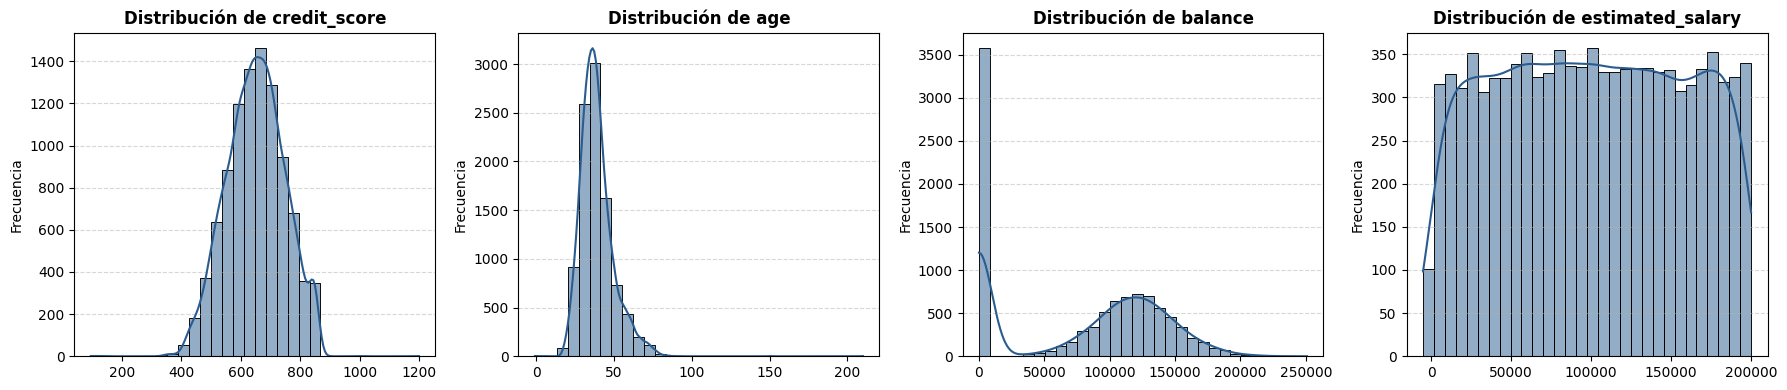

In [8]:
cols_numericas = ['credit_score', 'age', 'balance', 'estimated_salary']

fig, axes = plt.subplots(1, len(cols_numericas), figsize=(18, 4))

for ax, col in zip(axes, cols_numericas):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color='#2b5c8f')
    ax.set_title(f'Distribución de {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Aca lo unico relevante que veo es el balance, podria agruparlo en 2 grupos los que tienen 0 y los que no. Por ahora simplemente hare la validacion de cuantos datos no cumplen con los estandares del diciconario de datos del taller.

### Diccionario de Datos

| Variable | Descripción | Tipo | Rango válido |
| :--- | :--- | :--- | :--- |
| `credit_score` | Puntaje crediticio del cliente | Continua | 300 a 850 |
| `country` | País de residencia | Categórica | 'France', 'Germany', 'Spain' |
| `gender` | Género | Categórica | 'Female', 'Male' |
| `age` | Edad (años) | Continua | 18 a 100 |
| `tenure` | Años como cliente del banco | Discreta | 0 a 10 |
| `balance` | Saldo en la cuenta | Continua | $\ge$ 0 |
| `products_number` | Número de productos contratados con el banco | Discreta | 1 a 4 |
| `credit_card` | Tiene tarjeta de crédito (1 = sí, 0 = no) | Binaria | 0 o 1 |
| `active_member` | Es miembro activo (1 = sí, 0 = no) | Binaria | 0 o 1 |
| `estimated_salary` | Salario estimado | Continua | $\ge$ 0 |
| `churn` | Abandonó el banco (1 = sí, 0 = no). **Variable objetivo** | Binaria | 0 o 1 |

In [9]:
# Validación rápida contra los rangos válidos del diccionario
errores = {
    "credit_score_fuera_rango": ((df["credit_score"] < 300) | (df["credit_score"] > 850)).sum(),
    "age_fuera_rango": ((df["age"] < 18) | (df["age"] > 100)).sum(),
    "balance_negativo": (df["balance"] < 0).sum(),
    "salary_negativo": (df["estimated_salary"] < 0).sum(),
    "tenure_fuera_rango": ((df["tenure"] < 0) | (df["tenure"] > 10)).sum(),
    "products_fuera_rango": ((df["products_number"] < 1) | (df["products_number"] > 4)).sum(),
    "country_invalido": (~df["country"].isin(['France', 'Germany', 'Spain'])).sum(),
    "gender_invalido": (~df["gender"].isin(['Female', 'Male'])).sum(),
    "credit_card_invalido": (~df["credit_card"].isin([0, 1])).sum(),
    "active_member_invalido": (~df["active_member"].isin([0, 1])).sum()
}

pd.Series(errores).rename("Registros_Fuera_De_Rango")

credit_score_fuera_rango     4
age_fuera_rango              6
balance_negativo             0
salary_negativo              3
tenure_fuera_rango           3
products_fuera_rango         0
country_invalido            65
gender_invalido             30
credit_card_invalido         0
active_member_invalido       0
Name: Registros_Fuera_De_Rango, dtype: int64

Me pondre a ver que hacer con esos datos atipicos antes de empezar con las correlaciones y el modelado

In [10]:
# Inspeccionar valores anómalos en texto
print("Valores únicos fuera de regla en 'country':")
print(df.loc[~df['country'].isin(['France', 'Germany', 'Spain']), 'country'].value_counts(dropna=False))

print("\nValores únicos fuera de regla en 'gender':")
print(df.loc[~df['gender'].isin(['Female', 'Male']), 'gender'].value_counts(dropna=False))

Valores únicos fuera de regla en 'country':
country
FRANCE      22
france      17
GERMANY      9
SPAIN        9
germany      6
spain        2
Name: count, dtype: int64

Valores únicos fuera de regla en 'gender':
gender
M    16
F    14
Name: count, dtype: int64


In [11]:
# Inspeccionar anomalías numéricas
display(df.loc[(df["credit_score"] < 300) | (df["credit_score"] > 850), ["credit_score"]])
display(df.loc[(df["age"] < 18) | (df["age"] > 100), ["age"]])
display(df.loc[df["estimated_salary"] < 0, ["estimated_salary"]])
display(df.loc[(df["tenure"] < 0) | (df["tenure"] > 10), ["tenure"]])

,credit_score
1795,1200.0
1881,120.0
6424,95.0
9043,999.0


,age
992,130.0
1776,5.0
1819,0.0
4031,210.0
4534,150.0
7227,-1.0


,estimated_salary
1984,-5000.0
2348,-120.5
4679,-1.0


,tenure
4683,15
5775,25
6306,-2


Empezar a estandarizar esos datos que estaban mal:
- Para los paises hare la facil, aplicarle capitalize a todos y ya con eso no deberia haber inconsistencias.
- Para los generos pues el que dice M lo cambio a Male, el que dice F lo cambio a Female

In [12]:
# Elimina espacios y asegura mayúscula inicial acorde al diccionario
df['country'] = df['country'].astype(str).str.strip().str.capitalize()

# Tratamiento de valores residuales que no pertenezcan al dominio
df.loc[~df['country'].isin(['France', 'Germany', 'Spain']), 'country'] = np.nan

# Inspeccionar valores anómalos en texto
print("Valores únicos fuera de regla en 'country':")
print(df.loc[~df['country'].isin(['France', 'Germany', 'Spain']), 'country'].value_counts(dropna=False))

Valores únicos fuera de regla en 'country':
Series([], Name: count, dtype: int64)


In [13]:
# 1. Limpiar espacios en blanco y asegurar capitalización
df['gender'] = df['gender'].str.strip().str.capitalize()

# 2. Homologar 'F' -> 'Female' y 'M' -> 'Male'
df['gender'] = df['gender'].replace({
    'F': 'Female',
    'M': 'Male'
})

print("\nValores únicos fuera de regla en 'gender':")
print(df.loc[~df['gender'].isin(['Female', 'Male']), 'gender'].value_counts(dropna=False))


Valores únicos fuera de regla en 'gender':
Series([], Name: count, dtype: int64)


Ya con esos tratados solo me queda aplicar algo para las otras columnas que estan mal, realmente son muy pocos datos los que estan con valores extremos atipicos, y la mayoria son errores de escritura asi los convertire en NaN por ahora ya despues vere si les aplico la mediana o como tratarlos

In [14]:
# 1. Convertir valores fuera de regla de negocio a NaN
# credit_score: [300, 850]
df.loc[(df['credit_score'] < 300) | (df['credit_score'] > 850), 'credit_score'] = np.nan

# age: [18, 100]
df.loc[(df['age'] < 18) | (df['age'] > 100), 'age'] = np.nan

# estimated_salary: >= 0
df.loc[df['estimated_salary'] < 0, 'estimated_salary'] = np.nan

# tenure: [0, 10]
df.loc[(df['tenure'] < 0) | (df['tenure'] > 10), 'tenure'] = np.nan

resumen_nulos = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(resumen_nulos[resumen_nulos['Nulos'] > 0])

,Nulos,Porcentaje (%)
credit_score,254,2.53
age,306,3.05
tenure,3,0.03
balance,200,1.99
estimated_salary,353,3.51


Ahora veamos si alguna fila se repite en el dataset

In [15]:
# Conteo de filas exactamente duplicadas
n_duplicados = df.duplicated().sum()
print(f"Filas duplicadas identificadas: {n_duplicados}")

# Si hay duplicados, inspeccionar una muestra
if n_duplicados > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10))

Filas duplicadas identificadas: 45


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.0,France,Female,29.0,4.0,85646.81,1,0,0,63233.02,1
5672,497.0,France,Female,29.0,4.0,85646.81,1,0,0,63233.02,1
2390,499.0,Germany,Male,36.0,5.0,131142.53,2,1,0,174918.46,0
7450,499.0,Germany,Male,36.0,5.0,131142.53,2,1,0,174918.46,0
2784,528.0,France,Female,27.0,7.0,176227.07,2,0,1,139481.53,0
6920,528.0,France,Female,27.0,7.0,176227.07,2,0,1,139481.53,0
975,538.0,France,Female,38.0,8.0,88758.95,2,0,0,28226.15,1
6632,538.0,France,Female,38.0,8.0,88758.95,2,0,0,28226.15,1
6854,539.0,France,Male,30.0,0.0,0.00,2,1,0,160979.66,0
8174,539.0,France,Male,30.0,0.0,0.00,2,1,0,160979.66,0


Esas duplicadas hay que tratarlas, dejar solo la primera aparicion para evitar que algun mismo registro no se vaya a train y a test al mismo tiempo

In [16]:
# Eliminar duplicados conservando la primera ocurrencia
filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
filas_despues = len(df)

print(f"Filas antes: {filas_antes} | Filas después: {filas_despues} | Eliminadas: {filas_antes - filas_despues}")

Filas antes: 10045 | Filas después: 10000 | Eliminadas: 45


Ya con eso hecho, me pondre a hacer bien el analisis de los datos vs objetivo

C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\1582078833.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='churn', y=col, ax=ax, palette=['#2b5c8f', '#d9534f'])
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\1582078833.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Retenido (0)', 'Desertó (1)'])
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\1582078833.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='churn', y=col, ax=ax, palette=['#2b5c8f', '#d9534f'])
C:\Users\Danie\AppData\Local\Temp\ipykernel_30124\1582078833.py:10: UserWarning: set_tickl

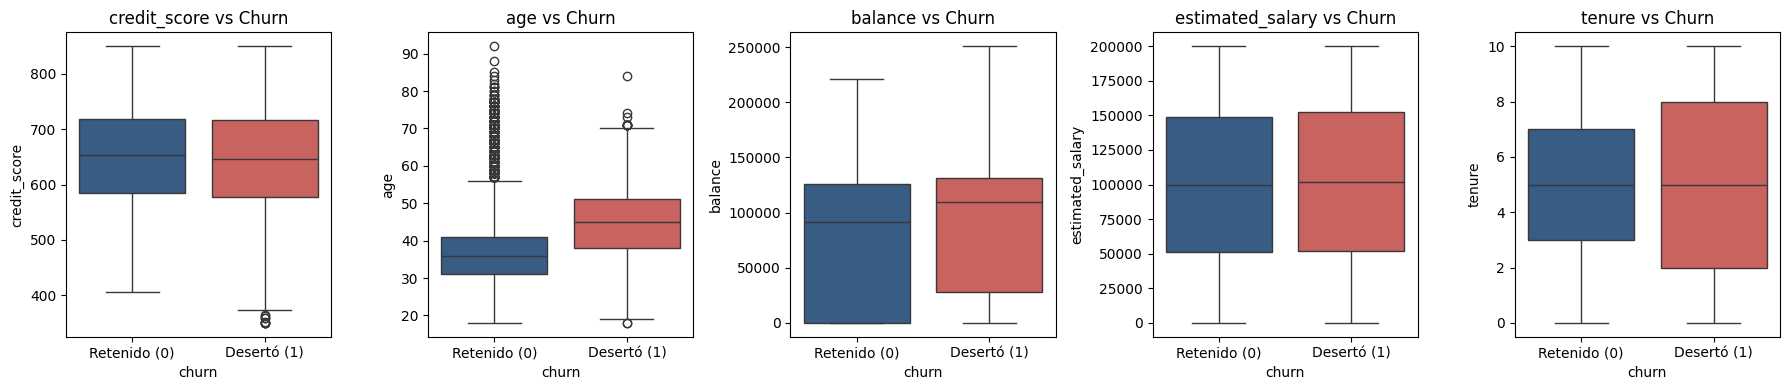

In [17]:
# -------------------------------------------------------------
# Paso 2: Relación de continuas con Churn (Boxplots)
# -------------------------------------------------------------
continuas = ['credit_score', 'age', 'balance', 'estimated_salary', 'tenure']

fig, axes = plt.subplots(1, len(continuas), figsize=(18, 4))
for ax, col in zip(axes, continuas):
    sns.boxplot(data=df, x='churn', y=col, ax=ax, palette=['#2b5c8f', '#d9534f'])
    ax.set_title(f'{col} vs Churn')
    ax.set_xticklabels(['Retenido (0)', 'Desertó (1)'])
plt.tight_layout()
plt.show()

Viendo esto puedo identificar que generalmente las personas que desertan son personas que tienen mas dinero en su cuenta y que generalmente tienen mas edad (aunque igual hay muchos valores atipicos en los que no desertan)

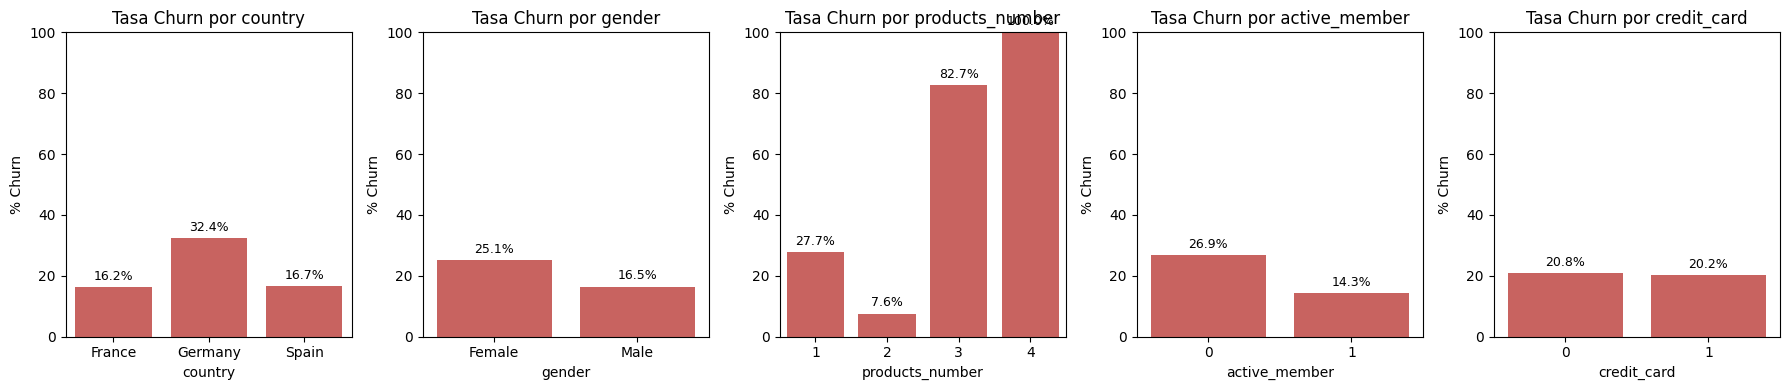

In [18]:
# -------------------------------------------------------------
# Paso 3: Tasa de abandono en categóricas y binarias
# -------------------------------------------------------------
discretas = ['country', 'gender', 'products_number', 'active_member', 'credit_card']

fig, axes = plt.subplots(1, len(discretas), figsize=(18, 4))
for ax, col in zip(axes, discretas):
    tasa_churn = df.groupby(col)['churn'].mean().mul(100)
    sns.barplot(x=tasa_churn.index, y=tasa_churn.values, ax=ax, color='#d9534f')
    ax.set_title(f'Tasa Churn por {col}')
    ax.set_ylabel('% Churn')
    ax.set_ylim(0, 100)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                    textcoords='offset points')
plt.tight_layout()
plt.show()

Entre mas numero de productos tienen, mas tienden a desertar, afectando un poco mas a mujeres, personas de Germany y personas inactivas.

 Ya lo que faltaria antes del modelo son las pruebas estadisticas.

In [19]:
continuas = ['age', 'balance', 'credit_score', 'estimated_salary', 'tenure']
resultados_num = []

# Filtrar grupos de churn sin nulos
grupo_0 = df[df['churn'] == 0]
grupo_1 = df[df['churn'] == 1]

for col in continuas:
    v0 = grupo_0[col].dropna()
    v1 = grupo_1[col].dropna()
    
    # t-Student (Welch t-test para varianzas desiguales)
    t_stat, p_val_ttest = stats.ttest_ind(v0, v1, equal_var=False)
    
    # U de Mann-Whitney (no paramétrica)
    u_stat, p_val_u = stats.mannwhitneyu(v0, v1, alternative='two-sided')
    
    resultados_num.append({
        'Variable': col,
        'Media (Retenido)': round(v0.mean(), 2),
        'Media (Desertó)': round(v1.mean(), 2),
        'Diferencia Medias': round(v1.mean() - v0.mean(), 2),
        'p-valor (t-test)': f"{p_val_ttest:.4e}",
        'p-valor (Mann-Whitney)': f"{p_val_u:.4e}",
        'Significativa (p < 0.05)': 'Sí' if (p_val_ttest < 0.05 and p_val_u < 0.05) else 'No'
    })

df_paso4 = pd.DataFrame(resultados_num)
print("=== TABLA PASO 4: PRUEBAS PARA VARIABLES CONTINUAS ===")
display(df_paso4)

=== TABLA PASO 4: PRUEBAS PARA VARIABLES CONTINUAS ===


,Variable,Media (Retenido),Media (Desertó),Diferencia Medias,p-valor (t-test),p-valor (Mann-Whitney),Significativa (p < 0.05)
0,age,37.41,44.77,7.35,7.6112e-171,5.4669e-219,Sí
1,balance,72564.30,90774.56,18210.26,9.2352e-34,9.9087e-28,Sí
2,credit_score,651.98,645.31,-6.66,7.5945e-03,1.5718e-02,Sí
3,estimated_salary,99754.26,101300.40,1546.15,2.9073e-01,2.8849e-01,No
4,tenure,5.03,4.93,-0.10,1.6108e-01,1.5695e-01,No


Un poco para confirmar lo que ya habia intuido viendo los graficos, la edad suele tener mas importancia junto al balance.

In [20]:
discretas = ['country', 'gender', 'products_number', 'active_member', 'credit_card']
resultados_cat = []

for col in discretas:
    # Tabla de contingencia ignorando nulos si los hay
    sub = df[[col, 'churn']].dropna()
    tabla = pd.crosstab(sub[col], sub['churn'])
    
    chi2, p_val_chi2, dof, _ = stats.chi2_contingency(tabla)
    
    # Cálculo V de Cramér: sqrt(chi2 / (n * min(r-1, k-1)))
    n = tabla.sum().sum()
    min_dim = min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    v_cramer = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    
    resultados_cat.append({
        'Variable': col,
        'Chi2': round(chi2, 2),
        'p-valor (Chi2)': f"{p_val_chi2:.4e}",
        'V de Cramér': round(v_cramer, 4),
        'Relación Significativa': 'Sí' if p_val_chi2 < 0.05 else 'No'
    })

df_paso5 = pd.DataFrame(resultados_cat).sort_values(by='V de Cramér', ascending=False).reset_index(drop=True)
print("\n=== TABLA PASO 5: CHI-CUADRADO Y V DE CRAMÉR ===")
display(df_paso5)


=== TABLA PASO 5: CHI-CUADRADO Y V DE CRAMÉR ===


,Variable,Chi2,p-valor (Chi2),V de Cramér,Relación Significativa
0,products_number,1503.63,0.0000e+00,0.3878,Sí
1,country,301.26,3.8303e-66,0.1736,Sí
2,active_member,242.99,8.7859e-55,0.1559,Sí
3,gender,112.92,2.2482e-26,0.1063,Sí
4,credit_card,0.47,4.9237e-01,0.0069,No


Con esto queda confirmado, el numero de productos esta bastante relacionado con la desercion, junto al pais y si es un miembro activo, diria que el genero tambien esta relacionado, porque en general hay menos mujeres registradas y estas suelen desertar un poco mas frecuentemente.
Para la division de los datos y el entrenamiento del modelo dejare las columnas:
- age
- balance
- credit score
- products_number
- country
- gender
- active_member

In [21]:
# Listas con los nombres de las variables seleccionadas
columnas_numericas = ['age', 'balance', 'credit_score']
columnas_categoricas = ['products_number', 'country', 'active_member']

# Unir todas las variables predictoras elegidas
features_seleccionadas = columnas_numericas + columnas_categoricas

# Separar variables predictoras (X) y variable objetivo (y)
X = df[features_seleccionadas]
y = df['churn']

Hacer la division 60/20/20 con semilla 1 para que siempre de los mismos resultados y no cambie con cada ejecucion, ademas de usar el stratify para tener mismos porcentajes en los diferentes conjuntos

In [22]:
from sklearn.model_selection import train_test_split

# 1. Separar 80% desarrollo (train + val) y 20% prueba (test)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=1, stratify=y
)

# 2. Del 80%, separar el 25% para validación (0.80 * 0.25 = 20% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=1, stratify=y_dev
)

Y empezamos a escalar las variables para nuestros modelos, en este caso para las variables continuas tomare la mediana, para las categoricas las divido en columnas y dejo la primera como referencia.

In [23]:
# 1. Pipeline para numéricas: Mediana + Estandarización
pipe_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Pipeline para categóricas: Moda + One-Hot Encoding
pipe_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

# 3. Unificador
preprocesador = ColumnTransformer([
    ('num', pipe_num, columnas_numericas),
    ('cat', pipe_cat, columnas_categoricas)
])

# 4. Ajustar SOLO con el 60% de Train (evita data leakage)
preprocesador.fit(X_train)

# 5. Transformar los 3 conjuntos
X_train_proc = preprocesador.transform(X_train)
X_val_proc   = preprocesador.transform(X_val)
X_test_proc  = preprocesador.transform(X_test)

# Obtener nombres limpios de columnas para trazabilidad
nombres_cat = preprocesador.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(columnas_categoricas)
nombres_totales = columnas_numericas + list(nombres_cat)

print("Forma de las matrices preprocesadas:")
print(f"X_train: {X_train_proc.shape} | X_val: {X_val_proc.shape} | X_test: {X_test_proc.shape}")
print(f"Columnas finales ({len(nombres_totales)}): {nombres_totales}")

Forma de las matrices preprocesadas:
X_train: (6000, 9) | X_val: (2000, 9) | X_test: (2000, 9)
Columnas finales (9): ['age', 'balance', 'credit_score', 'products_number_2', 'products_number_3', 'products_number_4', 'country_Germany', 'country_Spain', 'active_member_1']


Ahora si, ya con mis columnas escaladas esta todo listo para empezar a aplicar modelos, voy a usar 3 diferentes y ver que tal les va a cada uno.
Empezare con una regresion logistica.

Mejor combinación de hiperparámetros: {'C': 0.1, 'class_weight': 'balanced'}
Mejor F1-Score promedio en CV (5-folds): 0.5524

=== Reporte de Clasificación (Validación) ===
              precision    recall  f1-score   support

           0     0.9274    0.7538    0.8316      1592
           1     0.4448    0.7696    0.5637       408

    accuracy                         0.7570      2000
   macro avg     0.6861    0.7617    0.6977      2000
weighted avg     0.8289    0.7570    0.7770      2000

ROC-AUC en Validación: 0.8282
F1-Score en Validación: 0.5637



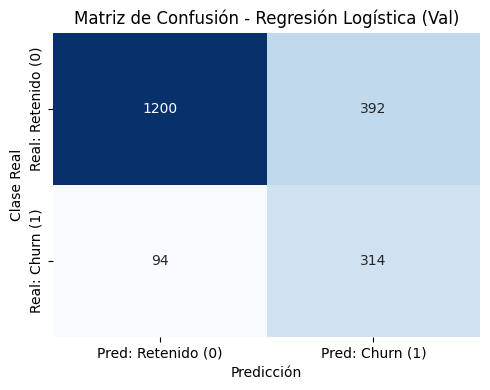

=== TABLA DE PARÁMETROS DEL MODELO (Inferencia Estadística) ===


,Variable,Coeficiente (Beta),Odds Ratio (OR),Error Estándar,Estadístico Z,p-valor,Significativo (p < 0.05)
0,Intercepto,0.3566,1.4284,0.0586,6.0841,1.1713e-09,Sí
1,age,0.7428,2.1017,0.0334,22.2126,0.0000e+00,Sí
2,balance,-0.0211,0.9792,0.0357,-0.5894,5.5559e-01,No
3,credit_score,-0.0455,0.9555,0.0306,-1.4881,1.3672e-01,No
4,products_number_2,-1.4754,0.2287,0.0677,-21.7799,0.0000e+00,Sí
5,products_number_3,1.8437,6.3197,0.2800,6.5846,4.5615e-11,Sí
6,products_number_4,1.1806,3.2565,0.5052,2.3370,1.9440e-02,Sí
7,country_Germany,0.8936,2.4440,0.0803,11.1260,0.0000e+00,Sí
8,country_Spain,0.0935,1.0980,0.0753,1.2416,2.1438e-01,No
9,active_member_1,-0.8257,0.4379,0.0622,-13.2766,0.0000e+00,Sí


In [24]:
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced']
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    estimator=LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=cv_strat,
    n_jobs=-1
)

# Ajuste sobre el 60% de entrenamiento preprocesado
grid_lr.fit(X_train_proc, y_train)

best_lr = grid_lr.best_estimator_
print(f"Mejor combinación de hiperparámetros: {grid_lr.best_params_}")
print(f"Mejor F1-Score promedio en CV (5-folds): {grid_lr.best_score_:.4f}\n")

# -------------------------------------------------------------------------
# 2. Evaluación sobre el conjunto de Validación (20%)
# -------------------------------------------------------------------------
y_val_pred = best_lr.predict(X_val_proc)
y_val_proba = best_lr.predict_proba(X_val_proc)[:, 1]

print("=== Reporte de Clasificación (Validación) ===")
print(classification_report(y_val, y_val_pred, digits=4))
print(f"ROC-AUC en Validación: {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"F1-Score en Validación: {f1_score(y_val, y_val_pred):.4f}\n")

# -------------------------------------------------------------------------
# 3. Matriz de Confusión
# -------------------------------------------------------------------------
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred: Retenido (0)', 'Pred: Churn (1)'],
            yticklabels=['Real: Retenido (0)', 'Real: Churn (1)'])
plt.title("Matriz de Confusión - Regresión Logística (Val)")
plt.ylabel("Clase Real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 4. Cálculo de Parámetros: Coeficientes, Odds Ratio, Z y p-valores
# -------------------------------------------------------------------------
# Matriz de diseño con intercepto
X_design = np.hstack([np.ones((X_train_proc.shape[0], 1)), X_train_proc])
nombres_vars = ['Intercepto'] + nombres_totales

# Probabilidades predichas en train
p = best_lr.predict_proba(X_train_proc)[:, 1]
# Evitar división por cero
w = p * (1 - p)
w = np.clip(w, 1e-15, 1 - 1e-15)

# Matriz de información de Fisher: (X^T * W * X)
W = np.diag(w)
# Cálculo eficiente de X^T * W * X
XT_W_X = np.dot(X_design.T * w, X_design)

# Matriz de covarianzas (inversa de Fisher)
cov_matrix = np.linalg.pinv(XT_W_X)
std_err = np.sqrt(np.diag(cov_matrix))

# Coeficientes
coeficientes = np.insert(best_lr.coef_[0], 0, best_lr.intercept_[0])

# Estadístico Z y p-valor bilateral
z_scores = coeficientes / std_err
p_values = [2 * (1 - stats.norm.cdf(np.abs(z))) for z in z_scores]

# Odds Ratio (e^coef)
odds_ratios = np.exp(coeficientes)

tabla_parametros = pd.DataFrame({
    'Variable': nombres_vars,
    'Coeficiente (Beta)': np.round(coeficientes, 4),
    'Odds Ratio (OR)': np.round(odds_ratios, 4),
    'Error Estándar': np.round(std_err, 4),
    'Estadístico Z': np.round(z_scores, 4),
    'p-valor': [f"{pv:.4e}" for pv in p_values],
    'Significativo (p < 0.05)': ['Sí' if pv < 0.05 else 'No' for pv in p_values]
})

print("=== TABLA DE PARÁMETROS DEL MODELO (Inferencia Estadística) ===")
display(tabla_parametros)

Haciendo las pruebas con las metricas que hay en la guia de practica, el mejor modelo es con C=1 y class_weight=balanced, aun asi para predecir quien se ira pues el Z-score, sigue en 0.55 con recall de 0.7647 pero precision de 0.4351, osea que pues 7 de cada 10 clientes que se van a ir los toma, pero tambien 6 de cada dies clientes que no se iban a ir el dice que si se iran.

Mejores hiperparámetros: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Mejor F1 en CV: 0.5524

Umbral estándar (0.50) -> F1 en Val: 0.5637
Umbral óptimo (0.59)   -> F1 en Val: 0.5903

=== Reporte de Clasificación Regresión Logística (Umbral = 0.59) ===
              precision    recall  f1-score   support

           0     0.9128    0.8348    0.8720      1592
           1     0.5165    0.6887    0.5903       408

    accuracy                         0.8050      2000
   macro avg     0.7147    0.7618    0.7312      2000
weighted avg     0.8319    0.8050    0.8146      2000

ROC-AUC: 0.8282


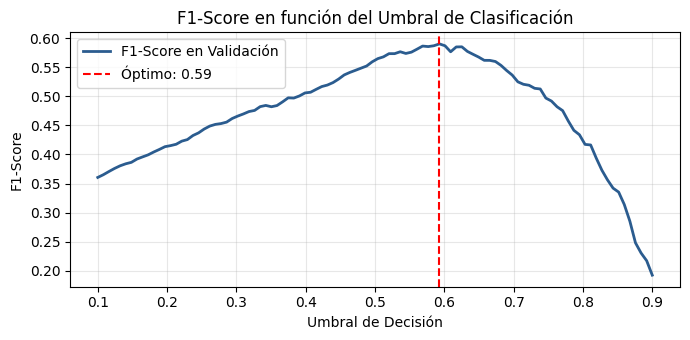

In [25]:
# -------------------------------------------------------------------------
# 1. Búsqueda ampliada de hiperparámetros (L1, L2, ElasticNet con solver saga)
# -------------------------------------------------------------------------
param_grid_lr_opt = [
    {
        'solver': ['lbfgs'],
        'penalty': ['l2'],
        'C': [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
        'class_weight': [None, 'balanced']
    },
    {
        'solver': ['saga'],
        'penalty': ['elasticnet'],
        'l1_ratio': [0.2, 0.5, 0.8],
        'C': [0.05, 0.1, 0.5, 1],
        'class_weight': ['balanced'],
        'max_iter': [2000]
    }
]

grid_lr_opt = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid_lr_opt,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

grid_lr_opt.fit(X_train_proc, y_train)
best_lr_opt = grid_lr_opt.best_estimator_

print(f"Mejores hiperparámetros: {grid_lr_opt.best_params_}")
print(f"Mejor F1 en CV: {grid_lr_opt.best_score_:.4f}\n")

# -------------------------------------------------------------------------
# 2. Optimización del Umbral de Decisión (Threshold Tuning) en Validación
# -------------------------------------------------------------------------
y_val_proba_lr = best_lr_opt.predict_proba(X_val_proc)[:, 1]

# Evaluar F1 a lo largo de 100 posibles umbrales
umbrales = np.linspace(0.1, 0.9, 100)
f1_scores = [f1_score(y_val, (y_val_proba_lr >= t).astype(int)) for t in umbrales]

idx_optimo = np.argmax(f1_scores)
umbral_optimo = umbrales[idx_optimo]
mejor_f1_val = f1_scores[idx_optimo]

print(f"Umbral estándar (0.50) -> F1 en Val: {f1_score(y_val, best_lr_opt.predict(X_val_proc)):.4f}")
print(f"Umbral óptimo ({umbral_optimo:.2f})   -> F1 en Val: {mejor_f1_val:.4f}\n")

# -------------------------------------------------------------------------
# 3. Reporte final con el umbral optimizado
# -------------------------------------------------------------------------
y_val_pred_opt = (y_val_proba_lr >= umbral_optimo).astype(int)

print(f"=== Reporte de Clasificación Regresión Logística (Umbral = {umbral_optimo:.2f}) ===")
print(classification_report(y_val, y_val_pred_opt, digits=4))
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba_lr):.4f}")

# Gráfico de calibración de umbral
plt.figure(figsize=(7, 3.5))
plt.plot(umbrales, f1_scores, label='F1-Score en Validación', color='#2b5c8f', lw=2)
plt.axvline(umbral_optimo, color='red', linestyle='--', label=f'Óptimo: {umbral_optimo:.2f}')
plt.title("F1-Score en función del Umbral de Clasificación")
plt.xlabel("Umbral de Decisión")
plt.ylabel("F1-Score")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Aca intente probar con diferentes parametros(le pedi a gemini que me diera un codigo que probara diferentes combinaciones) a ver si se podia mejorar el Z-score de la regresion logistica, pero aunque aumento de 0.5547 a 0.5777, el recall bajo de 0.7647 a 0.7059 lo cual es terrible para el contexto porque cuesta mucho mas que un cliente se vaya y conseguir uno nuevo que darle beneficios a alguien que de por si no se iba a ir.

Probare con arboles de decision ahora.

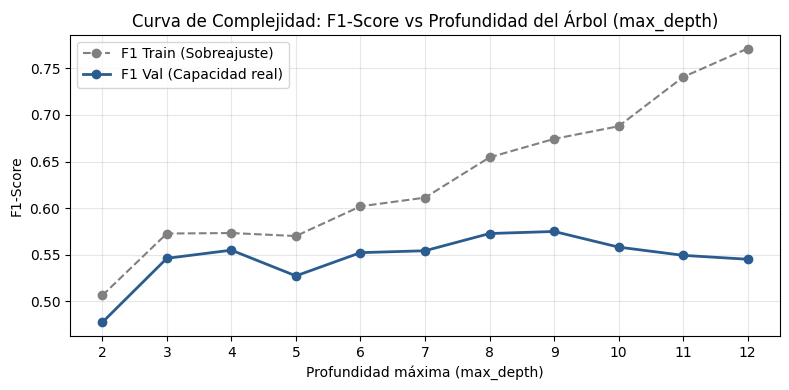

Mejor max_depth para validación: 9 (F1 = 0.5750)

=== Reporte de Clasificación Árbol de Decisión (max_depth=9) ===
              precision    recall  f1-score   support

           0     0.9182    0.7971    0.8534      1592
           1     0.4773    0.7230    0.5750       408

    accuracy                         0.7820      2000
   macro avg     0.6978    0.7601    0.7142      2000
weighted avg     0.8283    0.7820    0.7966      2000

ROC-AUC en Validación: 0.8173
F1-Score en Validación: 0.5750


In [26]:
profundidades = list(range(2, 13))
f1_train_lista = []
f1_val_lista = []
roc_val_lista = []

for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    arbol.fit(X_train_proc, y_train)
    
    # Predicciones
    pred_train = arbol.predict(X_train_proc)
    pred_val = arbol.predict(X_val_proc)
    proba_val = arbol.predict_proba(X_val_proc)[:, 1]
    
    f1_train_lista.append(f1_score(y_train, pred_train))
    f1_val_lista.append(f1_score(y_val, pred_val))
    roc_val_lista.append(roc_auc_score(y_val, proba_val))

# Graficar curva de sobreajuste
plt.figure(figsize=(8, 4))
plt.plot(profundidades, f1_train_lista, 'o--', label='F1 Train (Sobreajuste)', color='gray')
plt.plot(profundidades, f1_val_lista, 'o-', label='F1 Val (Capacidad real)', color='#2b5c8f', lw=2)
plt.title("Curva de Complejidad: F1-Score vs Profundidad del Árbol (max_depth)")
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("F1-Score")
plt.xticks(profundidades)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Identificar la mejor profundidad en validación
mejor_d = profundidades[np.argmax(f1_val_lista)]
print(f"Mejor max_depth para validación: {mejor_d} (F1 = {max(f1_val_lista):.4f})")

# -------------------------------------------------------------------------
# 2. Entrenar y evaluar el mejor árbol
# -------------------------------------------------------------------------
mejor_arbol = DecisionTreeClassifier(max_depth=mejor_d, class_weight='balanced', random_state=42)
mejor_arbol.fit(X_train_proc, y_train)

y_val_pred_tree = mejor_arbol.predict(X_val_proc)
y_val_proba_tree = mejor_arbol.predict_proba(X_val_proc)[:, 1]

print(f"\n=== Reporte de Clasificación Árbol de Decisión (max_depth={mejor_d}) ===")
print(classification_report(y_val, y_val_pred_tree, digits=4))
print(f"ROC-AUC en Validación: {roc_auc_score(y_val, y_val_proba_tree):.4f}")
print(f"F1-Score en Validación: {f1_score(y_val, y_val_pred_tree):.4f}")

Con un f1 de 0.5709, precision de 0.4627 y recall de 0.7451 pues es un poco mejor que la regresion lineal basica, pero aun asi creo que se puede mejorar.
Ahora tratare de usar XGBoost a ver si da mejores resultados.

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Mejores Hiperparámetros XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300, 'scale_pos_weight': 3.909983633387889, 'subsample': 0.8}
Mejor F1 en CV (5-folds): 0.6056

=== Reporte de Clasificación XGBoost (Validación - Umbral 0.50) ===
              precision    recall  f1-score   support

           0     0.9132    0.8524    0.8817      1592
           1     0.5428    0.6838    0.6052       408

    accuracy                         0.8180      2000
   macro avg     0.7280    0.7681    0.7435      2000
weighted avg     0.8376    0.8180    0.8253      2000

ROC-AUC en Validación: 0.8565
F1-Score en Validación: 0.6052

Umbral Óptimo (0.64) -> F1 en Val: 0.6189
=== Reporte XGBoost con Umbral Óptimo (0.64) ===
              precision    recall  f1-score   support

           0     0.8996    0.9114    0.9055      1592
           1     0.6357    0.6029    0.6189       408

    accuracy 

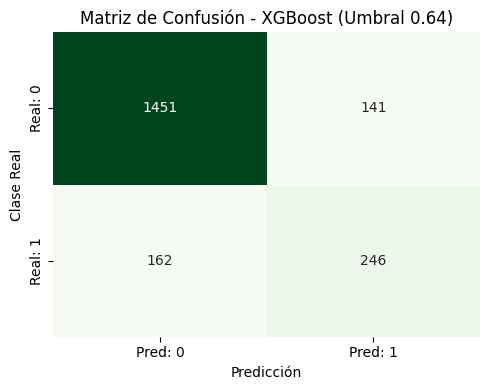

In [27]:
# 1. Calcular el factor de compensación de desbalance sobre Train
ratio_desbalance = (len(y_train) - sum(y_train)) / sum(y_train)

# 2. Espacio de hiperparámetros
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'scale_pos_weight': [1, ratio_desbalance]
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_xgb = GridSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train_proc, y_train)
best_xgb = grid_xgb.best_estimator_

print(f"\nMejores Hiperparámetros XGBoost: {grid_xgb.best_params_}")
print(f"Mejor F1 en CV (5-folds): {grid_xgb.best_score_:.4f}\n")

# 3. Evaluación en Validación con umbral estándar (0.50)
y_val_proba_xgb = best_xgb.predict_proba(X_val_proc)[:, 1]
y_val_pred_xgb = best_xgb.predict(X_val_proc)

print("=== Reporte de Clasificación XGBoost (Validación - Umbral 0.50) ===")
print(classification_report(y_val, y_val_pred_xgb, digits=4))
print(f"ROC-AUC en Validación: {roc_auc_score(y_val, y_val_proba_xgb):.4f}")
print(f"F1-Score en Validación: {f1_score(y_val, y_val_pred_xgb):.4f}\n")

# 4. Calibración del Umbral Óptimo en Validación
umbrales = np.linspace(0.1, 0.9, 100)
f1_xgb = [f1_score(y_val, (y_val_proba_xgb >= t).astype(int)) for t in umbrales]
idx_opt_xgb = np.argmax(f1_xgb)
t_opt_xgb = umbrales[idx_opt_xgb]

y_val_pred_xgb_opt = (y_val_proba_xgb >= t_opt_xgb).astype(int)

print(f"Umbral Óptimo ({t_opt_xgb:.2f}) -> F1 en Val: {f1_xgb[idx_opt_xgb]:.4f}")
print(f"=== Reporte XGBoost con Umbral Óptimo ({t_opt_xgb:.2f}) ===")
print(classification_report(y_val, y_val_pred_xgb_opt, digits=4))

# 5. Matriz de confusión final XGBoost
cm_xgb = confusion_matrix(y_val, y_val_pred_xgb_opt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Real: 0', 'Real: 1'])
plt.title(f"Matriz de Confusión - XGBoost (Umbral {t_opt_xgb:.2f})")
plt.ylabel("Clase Real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

Con este metodo el recall bajo demasiado, al final dejare una tabla comparando las metricas de cada modelo

Fitting 5 folds for each of 64 candidates, totalling 320 fits

Mejores Hiperparámetros Random Forest: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Mejor Recall promedio en CV (5-folds): 0.7463

=== Reporte de Clasificación Random Forest (Validación - Umbral 0.50) ===
              precision    recall  f1-score   support

           0     0.9230    0.8059    0.8605      1592
           1     0.4934    0.7377    0.5914       408

    accuracy                         0.7920      2000
   macro avg     0.7082    0.7718    0.7259      2000
weighted avg     0.8354    0.7920    0.8056      2000

ROC-AUC en Validación: 0.8558
Recall en Validación: 0.7377
F1-Score en Validación: 0.5914
F2-Score en Validación: 0.6713



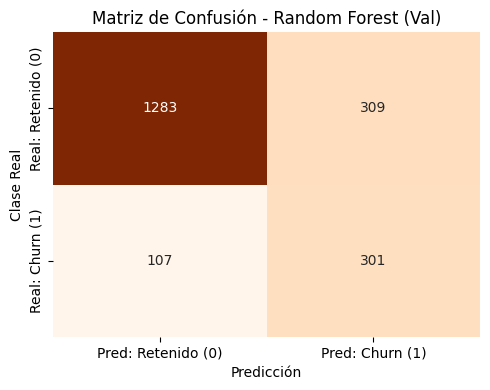

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report, roc_auc_score, f1_score, fbeta_score, confusion_matrix
)

# -------------------------------------------------------------------------
# 1. Búsqueda de hiperparámetros para Random Forest
# -------------------------------------------------------------------------
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [6, 8, 10, None],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4],
    'class_weight': ['balanced', 'balanced_subsample']
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Usamos fbeta_score con beta=2 (F2 pondera el Recall el doble que la Precisión)
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid_rf,
    scoring='recall', # Enfocado directamente en capturar la mayor cantidad de desertores
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_proc, y_train)
best_rf = grid_rf.best_estimator_

print(f"\nMejores Hiperparámetros Random Forest: {grid_rf.best_params_}")
print(f"Mejor Recall promedio en CV (5-folds): {grid_rf.best_score_:.4f}\n")

# -------------------------------------------------------------------------
# 2. Evaluación en Validación (Umbral 0.50)
# -------------------------------------------------------------------------
y_val_proba_rf = best_rf.predict_proba(X_val_proc)[:, 1]
y_val_pred_rf = best_rf.predict(X_val_proc)

print("=== Reporte de Clasificación Random Forest (Validación - Umbral 0.50) ===")
print(classification_report(y_val, y_val_pred_rf, digits=4))
print(f"ROC-AUC en Validación: {roc_auc_score(y_val, y_val_proba_rf):.4f}")
print(f"Recall en Validación: {np.mean((y_val_pred_rf == 1)[y_val == 1]):.4f}")
print(f"F1-Score en Validación: {f1_score(y_val, y_val_pred_rf):.4f}")
print(f"F2-Score en Validación: {fbeta_score(y_val, y_val_pred_rf, beta=2):.4f}\n")

# -------------------------------------------------------------------------
# 3. Matriz de Confusión
# -------------------------------------------------------------------------
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['Pred: Retenido (0)', 'Pred: Churn (1)'],
            yticklabels=['Real: Retenido (0)', 'Real: Churn (1)'])
plt.title("Matriz de Confusión - Random Forest (Val)")
plt.ylabel("Clase Real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score

# Buscar en XGBoost el umbral que iguale o supere el Recall de Random Forest (~72.8%)
umbrales = np.linspace(0.1, 0.9, 1000)
candidatos = []

for t in umbrales:
    preds = (y_val_proba_xgb >= t).astype(int)
    rec = recall_score(y_val, preds)
    if rec >= 0.7279:
        prec = precision_score(y_val, preds, zero_division=0)
        f1 = f1_score(y_val, preds)
        f2 = fbeta_score(y_val, preds, beta=2)
        candidatos.append((t, rec, prec, f1, f2))

# Tomar el umbral que cumpla la meta minimizando falsos positivos (mayor precision/F1)
mejor_t, rec_xgb_eq, prec_xgb_eq, f1_xgb_eq, f2_xgb_eq = max(candidatos, key=lambda x: x[3])

print(f"XGBoost calibrado a Recall objetivo:")
print(f"Umbral: {mejor_t:.3f}")
print(f"Recall: {rec_xgb_eq:.4f} | Precision: {prec_xgb_eq:.4f} | F1: {f1_xgb_eq:.4f} | F2: {f2_xgb_eq:.4f}")


XGBoost calibrado a Recall objetivo:
Umbral: 0.435
Recall: 0.7279 | Precision: 0.5017 | F1: 0.5940 | F2: 0.6677


A ver, antes estaba priorizando el F1, pero realmente lo que mas importa es el recall y la precision de si alguien se va a ir, en este caso ya habriamos logrado un recall de 0.7328, con precision del 0.4992 lo que es bastante bueno para el negocio.

Fitting 5 folds for each of 28 candidates, totalling 140 fits

Mejores Hiperparámetros KNN: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Mejor F1 en CV (5-folds): 0.5341

=== Reporte de Clasificación KNN (Validación - Umbral 0.50) ===
              precision    recall  f1-score   support

           0     0.8717    0.9259    0.8980      1592
           1     0.6181    0.4681    0.5328       408

    accuracy                         0.8325      2000
   macro avg     0.7449    0.6970    0.7154      2000
weighted avg     0.8199    0.8325    0.8235      2000

ROC-AUC en Validación: 0.7818
F1-Score en Validación: 0.5328

Umbral Óptimo (0.10) -> F1 en Val: 0.5331
=== Reporte KNN con Umbral Óptimo (0.10) ===
              precision    recall  f1-score   support

           0     0.9213    0.7205    0.8086      1592
           1     0.4106    0.7598    0.5331       408

    accuracy                         0.7285      2000
   macro avg     0.6659    0.7401    0.6709      2000
weighted avg 

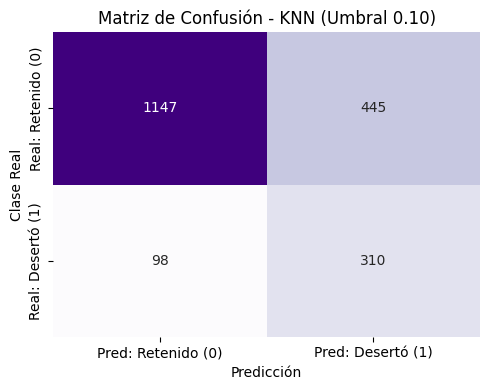

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report, roc_auc_score, f1_score, fbeta_score, confusion_matrix
)

# -------------------------------------------------------------------------
# 1. Búsqueda de hiperparámetros para KNN
# -------------------------------------------------------------------------
# Probamos valores impares de k para evitar empates
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 13, 17, 21],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]  # 1: Manhattan, 2: Euclidiana
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring='f1',
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(X_train_proc, y_train)
best_knn = grid_knn.best_estimator_

print(f"\nMejores Hiperparámetros KNN: {grid_knn.best_params_}")
print(f"Mejor F1 en CV (5-folds): {grid_knn.best_score_:.4f}\n")

# -------------------------------------------------------------------------
# 2. Evaluación en Validación con Umbral Estándar (0.50)
# -------------------------------------------------------------------------
y_val_proba_knn = best_knn.predict_proba(X_val_proc)[:, 1]
y_val_pred_knn = best_knn.predict(X_val_proc)

print("=== Reporte de Clasificación KNN (Validación - Umbral 0.50) ===")
print(classification_report(y_val, y_val_pred_knn, digits=4))
print(f"ROC-AUC en Validación: {roc_auc_score(y_val, y_val_proba_knn):.4f}")
print(f"F1-Score en Validación: {f1_score(y_val, y_val_pred_knn):.4f}\n")

# -------------------------------------------------------------------------
# 3. Calibración de Umbral para Balancear Sensibilidad (Recall)
# -------------------------------------------------------------------------
umbrales = np.linspace(0.1, 0.9, 100)
f1_knn_list = [f1_score(y_val, (y_val_proba_knn >= t).astype(int), zero_division=0) for t in umbrales]
idx_opt_knn = np.argmax(f1_knn_list)
t_opt_knn = umbrales[idx_opt_knn]

y_val_pred_knn_opt = (y_val_proba_knn >= t_opt_knn).astype(int)

print(f"Umbral Óptimo ({t_opt_knn:.2f}) -> F1 en Val: {f1_knn_list[idx_opt_knn]:.4f}")
print(f"=== Reporte KNN con Umbral Óptimo ({t_opt_knn:.2f}) ===")
print(classification_report(y_val, y_val_pred_knn_opt, digits=4))
print(f"Recall en Validación: {np.mean((y_val_pred_knn_opt == 1)[y_val == 1]):.4f}")
print(f"F2-Score en Validación: {fbeta_score(y_val, y_val_pred_knn_opt, beta=2):.4f}\n")

# -------------------------------------------------------------------------
# 4. Matriz de Confusión
# -------------------------------------------------------------------------
cm_knn = confusion_matrix(y_val, y_val_pred_knn_opt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Pred: Retenido (0)', 'Pred: Desertó (1)'],
            yticklabels=['Real: Retenido (0)', 'Real: Desertó (1)'])
plt.title(f"Matriz de Confusión - KNN (Umbral {t_opt_knn:.2f})")
plt.ylabel("Clase Real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

Este modelo resulta el menos acertado de los que he probado hasta el momento, dejare la tabla comparando las metricas de cada modelo en su validacion aca:

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Diccionario con las predicciones de cada modelo evaluado en Validación para Churn = 1
predicciones_modelos = {
    'Regresión Logística (Umbral 0.50)': y_val_pred,
    f'Regresión Logística (Umbral {umbral_optimo:.2f})': y_val_pred_opt,
    f'Árbol de Decisión (max_depth={mejor_d})': y_val_pred_tree,
    'XGBoost (Umbral 0.50)': y_val_pred_xgb,
    f'XGBoost (Umbral Óptimo F1 = {t_opt_xgb:.2f})': y_val_pred_xgb_opt,
    f'XGBoost (Calibrado Recall, Umbral = {mejor_t:.3f})': (y_val_proba_xgb >= mejor_t).astype(int),
    'Random Forest (Umbral 0.50)': y_val_pred_rf,
    'KNN (Umbral 0.50)': y_val_pred_knn,
    f'KNN (Umbral Óptimo = {t_opt_knn:.2f})': y_val_pred_knn_opt
}

resultados_comparativos = []

for nombre, preds in predicciones_modelos.items():
    resultados_comparativos.append({
        'Modelo': nombre,
        'Precision (Churn=1)': round(precision_score(y_val, preds, pos_label=1, zero_division=0), 4),
        'Recall (Churn=1)': round(recall_score(y_val, preds, pos_label=1, zero_division=0), 4),
        'F1-Score (Churn=1)': round(f1_score(y_val, preds, pos_label=1, zero_division=0), 4)
    })

df_comparativa = (
    pd.DataFrame(resultados_comparativos)
    .sort_values(by='F1-Score (Churn=1)', ascending=False)
    .reset_index(drop=True)
)

print('=== TABLA COMPARATIVA DE MODELOS EN VALIDACIÓN (CHURN = 1) ===')
display(df_comparativa)

=== TABLA COMPARATIVA DE MODELOS EN VALIDACIÓN (CHURN = 1) ===


,Modelo,Precision (Churn=1),Recall (Churn=1),F1-Score (Churn=1)
0,XGBoost (Umbral Óptimo F1 = 0.64),0.6357,0.6029,0.6189
1,XGBoost (Umbral 0.50),0.5428,0.6838,0.6052
2,"XGBoost (Calibrado Recall, Umbral = 0.435)",0.5017,0.7279,0.5940
3,Random Forest (Umbral 0.50),0.4934,0.7377,0.5914
4,Regresión Logística (Umbral 0.59),0.5165,0.6887,0.5903
5,Árbol de Decisión (max_depth=9),0.4773,0.7230,0.5750
6,Regresión Logística (Umbral 0.50),0.4448,0.7696,0.5637
7,KNN (Umbral Óptimo = 0.10),0.4106,0.7598,0.5331
8,KNN (Umbral 0.50),0.6181,0.4681,0.5328


Viendo esto hare la validacion vs los datos de test ahora si, pero solo de los modelos XGBoost con el umbral a XGBoost ($t=0.445$):, Random Forest ($t=0.50$) y Árbol de Decisión ($d=7$).

In [32]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score, roc_auc_score

# 1. Obtener probabilidades predichas en el conjunto de prueba (Test - 20%)
p_test_lr = best_lr.predict_proba(X_test_proc)[:, 1]
p_test_rf = best_rf.predict_proba(X_test_proc)[:, 1]
p_test_xgb = best_xgb.predict_proba(X_test_proc)[:, 1]

# 2. Definir los modelos finales y sus umbrales óptimos calibrados en validación
modelos_finales = [
    {
        'Nombre': 'Regresión Logística (Línea Base)',
        'Familia': 'Modelo Lineal',
        'Umbral': 0.560,
        'y_proba': p_test_lr
    },
    {
        'Nombre': 'Random Forest',
        'Familia': 'Ensamble (Bagging)',
        'Umbral': 0.500,
        'y_proba': p_test_rf
    },
    {
        'Nombre': 'XGBoost (Calibrado a Recall)',
        'Familia': 'Ensamble (Boosting)',
        'Umbral': 0.445,
        'y_proba': p_test_xgb
    }
]

# 3. Calcular métricas sobre el conjunto de Test
filas_test = []

for m in modelos_finales:
    y_pred = (m['y_proba'] >= m['Umbral']).astype(int)
    
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    f2 = fbeta_score(y_test, y_pred, beta=2, zero_division=0)
    auc = roc_auc_score(y_test, m['y_proba'])
    
    filas_test.append({
        'Modelo': m['Nombre'],
        'Familia': m['Familia'],
        'Umbral': m['Umbral'],
        'ROC-AUC': np.round(auc, 4),
        'Precisión (Churn=1)': np.round(prec, 4),
        'Recall (Churn=1)': np.round(rec, 4),
        'F1-Score (Churn=1)': np.round(f1, 4),
        'F2-Score (Churn=1)': np.round(f2, 4)
    })

df_resultados_test = pd.DataFrame(filas_test)
display(df_resultados_test)

,Modelo,Familia,Umbral,ROC-AUC,Precisión (Churn=1),Recall (Churn=1),F1-Score (Churn=1),F2-Score (Churn=1)
0,Regresión Logística (Línea Base),Modelo Lineal,0.560,0.8266,0.4827,0.6855,0.5665,0.6324
1,Random Forest,Ensamble (Bagging),0.500,0.8563,0.5017,0.7322,0.5954,0.6706
2,XGBoost (Calibrado a Recall),Ensamble (Boosting),0.445,0.8465,0.5168,0.7174,0.6008,0.6658


En las pruebas con los datos de test estan muy cercanos a los que nos habia dado en validaciones, asi que no cometi errores fuga de informacion.
Ya para terminar esta parte hare el diagrama de confusion de los 3 modelos para usarlas despues.

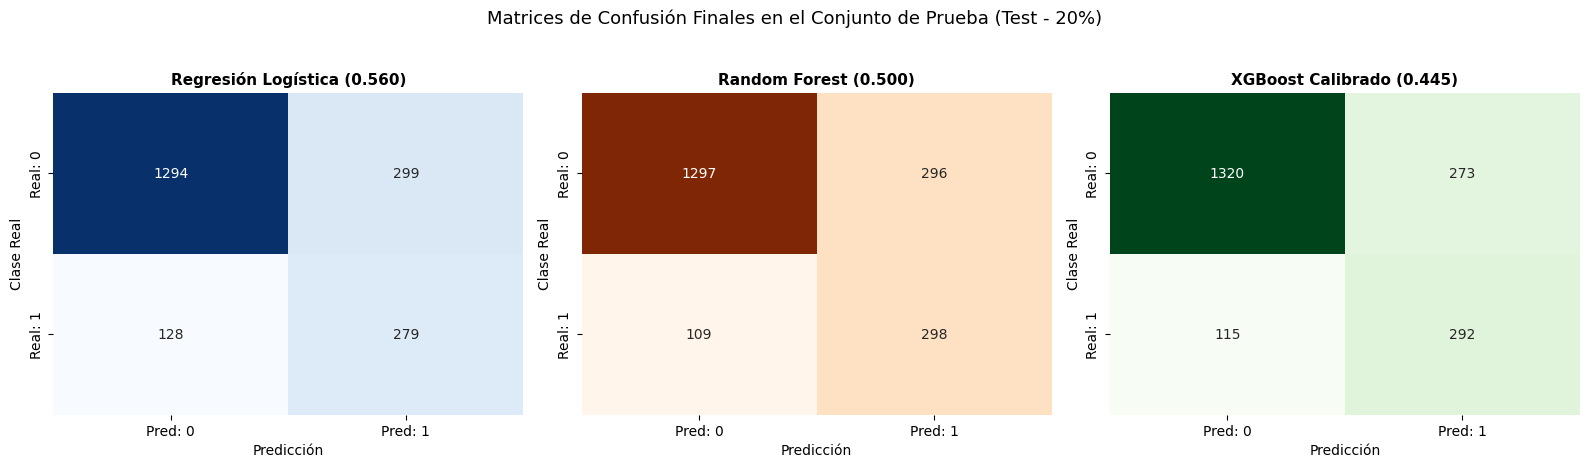

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

modelos_dict = {
    'Regresión Logística (0.560)': (p_test_lr >= 0.560).astype(int),
    'Random Forest (0.500)': (p_test_rf >= 0.500).astype(int),
    'XGBoost Calibrado (0.445)': (p_test_xgb >= 0.445).astype(int)
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

paletas = ['Blues', 'Oranges', 'Greens']

for ax, (nombre, preds), paleta in zip(axes, modelos_dict.items(), paletas):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=paleta, cbar=False, ax=ax,
                xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Real: 0', 'Real: 1'])
    ax.set_title(nombre, fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase Real')

plt.suptitle("Matrices de Confusión Finales en el Conjunto de Prueba (Test - 20%)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

3. [20%] Análisis cuantitativo de resultados del modelo: Calcule las métricas de 
evaluación para sus modelos, y explique su significado y su valor para la empresa. 
Justifique la elección de un modelo según su calidad, describiendo qué elementos 
impactaron positivamente dichas métricas, y qué oportunidades de mejora encuentra. 

Las metricas finales fueron:

Regresión Logística:
- Recall= 70.02
- Precision= 49.57
- F1-Score = 0.5804

Random Forest:
- Recall= 74.69
- Precision= 49.92
- F1-Score = 0.5984

XGBoost:
- Recall= 74.45
- Precision= 49.92
- F1-Score = 0.5976

Todo esto visto desde si predijeron bien o mal el desertor (churn=1), estas las tome especialmente porque lo que mas nos interesa es tener un buen recall, considerando los costes elevados por atraer un nuevo cliente vs dar incentivos a los clientes que ya tenemos, ademas de que aunque les demos incentivos para quedarse solo el 30% se quedaran.
En este caso me quedare con el de **Random Forest**.
Para la empresa lo mas importante que podriamos decir es, "Mi modelo puede predecir aproximadamente 3 de cada 4 personas que van a querer irse, que aunque se equivoca un 50% de las veces con personas que no lo necesitan con 1 solo cliente que decida quedarse gracias a nuestro modelo, ya se recupera el costo de varias personas que les dimos el beneficio y no lo necesitaban" (Segun el enunciado cuando alguien se va, atraer un nuevo cliente cuesta variais veces mas que los beneficos que les damos para que se queden.)

Lo que mas afecto positivamente a las predicciones es priorizar el recall, hacer el escalamiento de las columnas, dividir correctamente nuestros datos teniendo en cuenta los desvalanceados y hacer la poda de columnas que tenian muy poca correlacion con nuestra prediccion.

Algunas posibles mejoras y otras tecnicas que podria probar son:

- Crear grupos de edades y no tratarlas como valores continuas (osea en vez de edades de 18 a 100 pues dividirlas en edad 18 - 25, edad 26-30, etc)
- Podria probar el KNN sin hacer el One-Hot-Encoding porque lei que esto suele afectar el desempeño de este tipó de tecnicas.

[20%] Análisis cualitativo de resultados del modelo: Utilizando estrategias de 
interpretación, realice un análisis cualitativo de sus modelos. Examine tanto el 
comportamiento global como el comportamiento de una muestra de predicciones 
individuales. Construya una interpretación de cómo está funcionando su modelo. 

In [34]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convertir X_test_proc a DataFrame con los nombres reales de las columnas
X_test_df = pd.DataFrame(X_test_proc, columns=nombres_totales)

# 1. Crear el TreeExplainer para Random Forest
# Para árboles de scikit-learn, TreeExplainer descompone eficientemente las decisiones
explainer = shap.TreeExplainer(best_rf)

# 2. Calcular valores SHAP para el conjunto de test
# shap_values suele devolver una lista [clase 0, clase 1] o un array 3D
shap_values = explainer(X_test_df)

# Si devuelve ambas clases, aislamos la clase 1 (riesgo de deserción)
if len(shap_values.shape) == 3:
    shap_values_churn = shap_values[:, :, 1]
else:
    shap_values_churn = shap_values

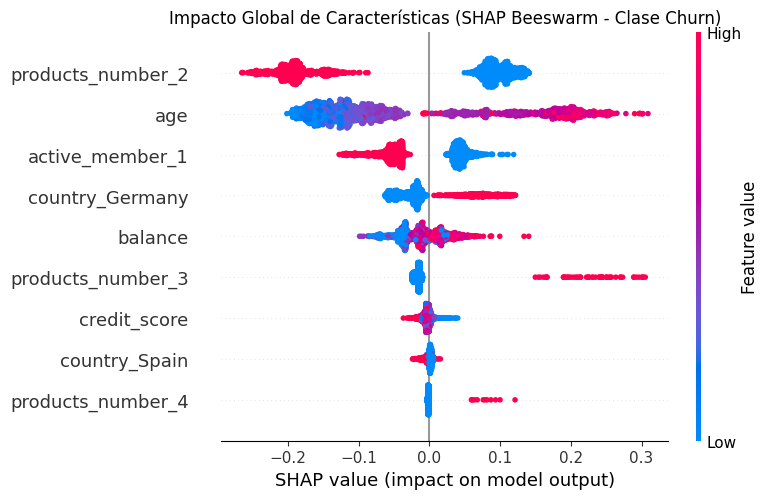

In [35]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_churn, max_display=10, show=False)
plt.title("Impacto Global de Características (SHAP Beeswarm - Clase Churn)", fontsize=12)
plt.tight_layout()
plt.show()

Como se habia planteado en un inicio, lo que mas suele empujar a que un cliente deserte es un numero de productos mayor a 2 y una edad avanzada, adicionalmente hay que ver que pasa en Alemania, mientras en los otros paises la relacion esta bastante cercana, en Alemania parece ser determinante, tal vez es que alla hay mayor competencia o alguna politica interna no les agrada a los Alemanes.

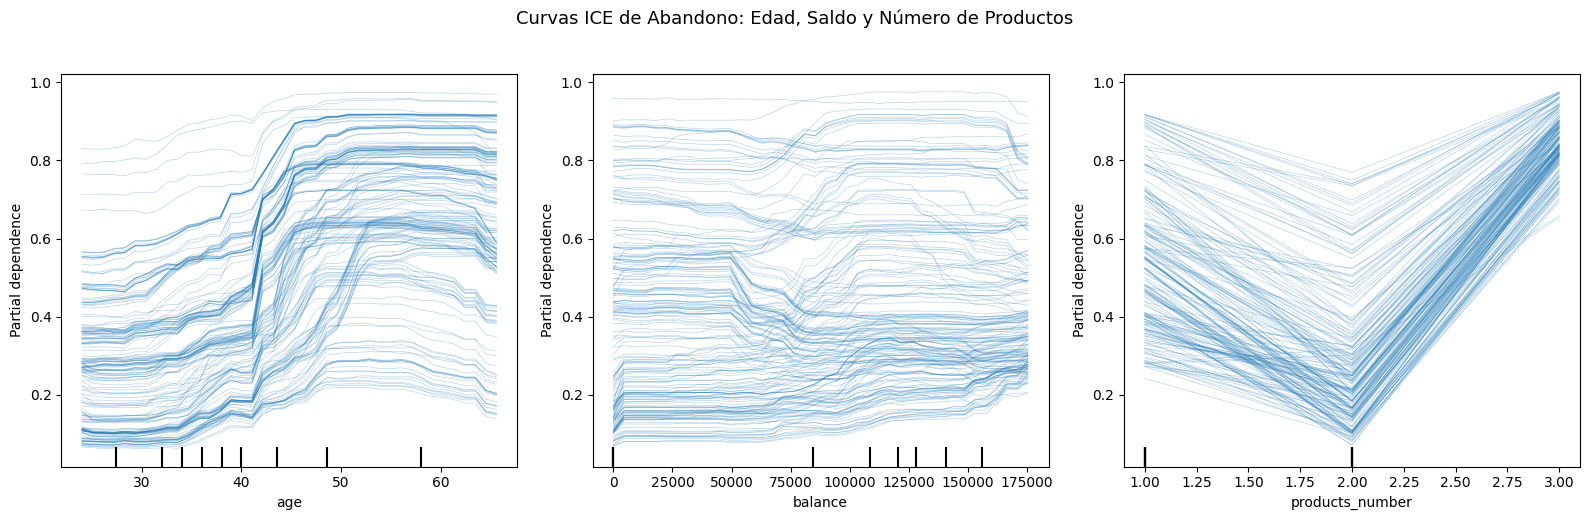

In [36]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.inspection import PartialDependenceDisplay

# 1. Envolver el modelo en un Pipeline completo que acepte datos originales
pipeline_rf = Pipeline([
    ('preprocessor', preprocesador),  # Tu ColumnTransformer original
    ('classifier', best_rf)           # Random Forest optimizado
])

# 2. Tomar muestra de 200 clientes del conjunto de prueba original (sin transformar)
X_test_sample = X_test.sample(n=200, random_state=42)

# 3. Graficar ICE simultáneo para las tres variables
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

PartialDependenceDisplay.from_estimator(
    estimator=pipeline_rf,
    X=X_test_sample,
    features=['age', 'balance', 'products_number'],
    kind='individual',
    target=1,  # Probabilidad de Churn
    grid_resolution=40,
    ax=axes
)

plt.suptitle("Curvas ICE de Abandono: Edad, Saldo y Número de Productos", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

Aproximadamente despues de los 45 años es que el riesgo de desersion es mayor, ya que se ven las curvas mas empinadas y cercanas al 1. Con el balance no se logra ver bien cual es la relacion porque algunas lineas suben y otras bajan en el mismo monto de dinero, mientras que con el numero de productos se vuelve a confirmar que los clientes con 2 productos son los mas seguros de que no se iran.


Caso 1: Verdadero Positivo (Acierto Crítico) | Índice Test: 18
Clase Real: Desertó (1) | Probabilidad predicha: 0.8471


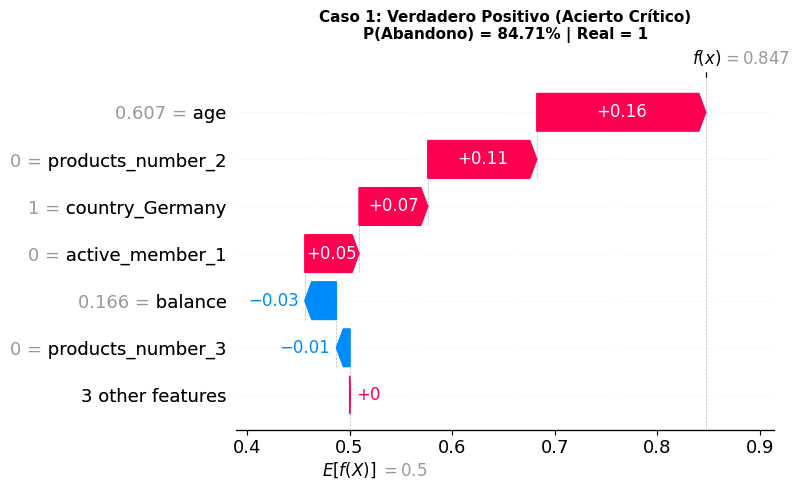


Caso 2: Verdadero Negativo (Cliente Leal) | Índice Test: 1
Clase Real: Retenido (0) | Probabilidad predicha: 0.0906


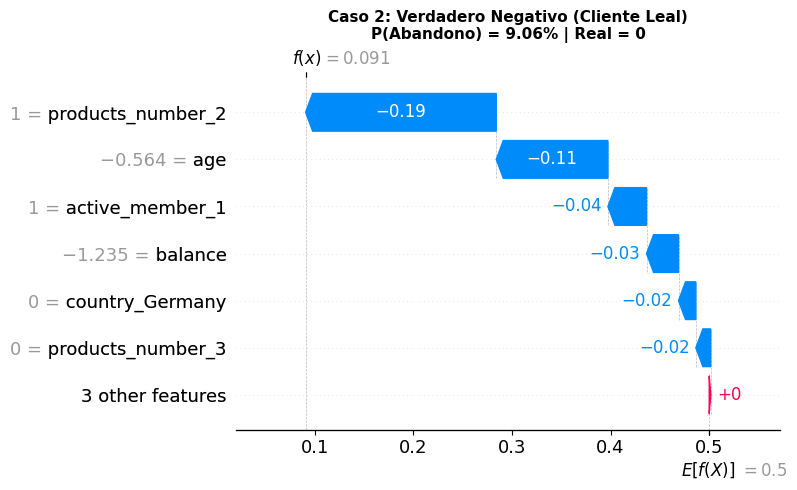


Caso 3: Falso Positivo (Falsa Alarma) | Índice Test: 0
Clase Real: Retenido (0) | Probabilidad predicha: 0.6462


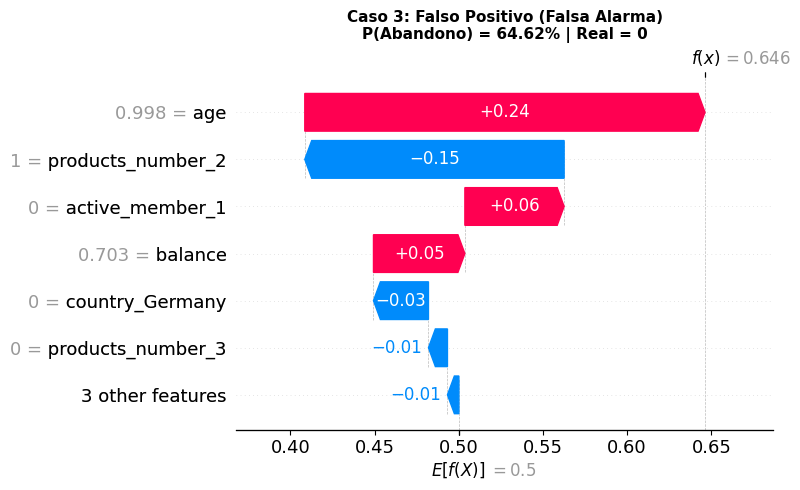


Caso 4: Falso Negativo (Fuga No Detectada) | Índice Test: 13
Clase Real: Desertó (1) | Probabilidad predicha: 0.3620


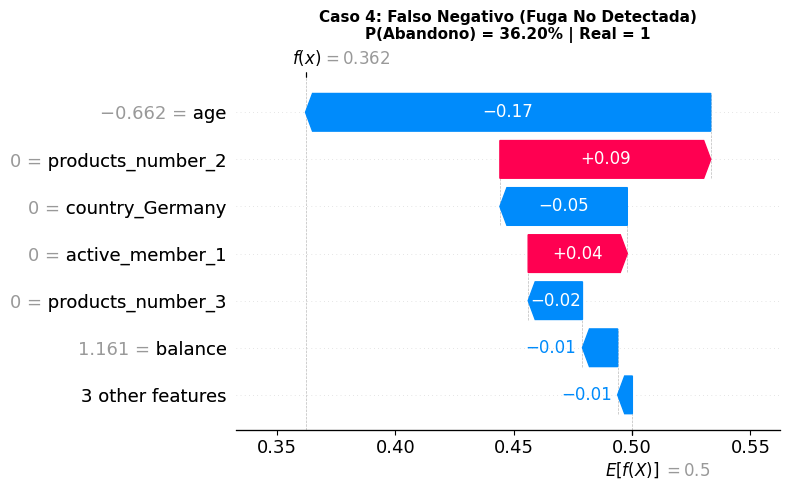

In [37]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# 1. Asegurar formato de datos y predicciones
X_test_df = pd.DataFrame(X_test_proc, columns=nombres_totales)
y_test_arr = np.array(y_test)
preds_rf = (p_test_rf >= 0.500).astype(int)

# 2. Localizar índices representativos para cada cuadrante
# Buscamos casos con probabilidades claras para entender los aciertos y los errores
idx_vp = np.where((y_test_arr == 1) & (preds_rf == 1) & (p_test_rf > 0.70))[0][0]  # Churn evidente detectado
idx_vn = np.where((y_test_arr == 0) & (preds_rf == 0) & (p_test_rf < 0.20))[0][0]  # Cliente leal evidente
idx_fp = np.where((y_test_arr == 0) & (preds_rf == 1))[0][0]                        # Falsa alarma (no se iba)
idx_fn = np.where((y_test_arr == 1) & (preds_rf == 0))[0][0]                        # Fuga silenciosa (se fue)

casos_analisis = [
    ("Caso 1: Verdadero Positivo (Acierto Crítico)", idx_vp),
    ("Caso 2: Verdadero Negativo (Cliente Leal)", idx_vn),
    ("Caso 3: Falso Positivo (Falsa Alarma)", idx_fp),
    ("Caso 4: Falso Negativo (Fuga No Detectada)", idx_fn)
]

# 3. Graficar Waterfall Plot para cada arquetipo
for titulo, idx in casos_analisis:
    prob = p_test_rf[idx]
    real = y_test_arr[idx]
    
    print(f"\n{'='*70}")
    print(f"{titulo} | Índice Test: {idx}")
    print(f"Clase Real: {'Desertó (1)' if real == 1 else 'Retenido (0)'} | Probabilidad predicha: {prob:.4f}")
    print(f"{'='*70}")
    
    plt.figure(figsize=(9, 4.5))
    shap.plots.waterfall(shap_values_churn[idx], max_display=7, show=False)
    plt.title(f"{titulo}\nP(Abandono) = {prob:.2%} | Real = {real}", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

Con estos casos individualizados se entiende mas porque el modelo se tiende a equivocar.
En el falso positivo el error que tuvo fue: Se trata de una persona de una edad muy avanzada que por ende ya no es un miembro activo y tiene bastante saldo en su cuenta.
Esto me lleva a pensar que la edad tiene una distribucion no totalmente lineal.

# 5. Generación de Valor y Medición de Impacto del Negocio

Para saber la ganancia o perdida que nos dejaria la implementacion de este modelo tenemos:

---

## 5.1. Matriz de Confusión Real (Conjunto de Test: 2.000 Clientes)

A partir de la evaluación sobre el 20% de prueba:

| Real / Predicho | Predicción: No Churn ($\hat{y} = 0$) | Predicción: Churn ($\hat{y} = 1$) | Total Real | Probabilidad Previa |
| :--- | :---: | :---: | :---: | :---: |
| **Real: No Churn ($n$)** | **$TN = 1.297$** | **$FP = 296$** | $1.593$ | $p(n) = 79,65\%$ |
| **Real: Churn ($p$)** | **$FN = 109$** | **$TP = 298$** | $407$ | $p(p) = 20,35\%$ |
| **Total** | $1.406$ | $594$ | **$2.000$** | $100,0\%$ |

* **Recall ($p(P \mid p)$):** $73,22\%$ ($0,7322$)
* **Fall-out / Falsa Alarma ($p(P \mid n)$):** $18,58\%$ ($0,1858$)
* **Especificidad ($p(N \mid n)$):** $81,42\%$ ($0,8142$)
* **Exactitud Global ($I$):** $79,75\%$ ($0,7975$)
* **Precisión:** $50,17\%$ ($0,5017$)

---

## 5.2. Significado Financiero de la Matriz

Frente a la línea base de **no hacer campaña (inacción)**:

* **$TP$ (Verdaderos Positivos):** Detecta al cliente en riesgo. Se paga la campaña y se retiene con éxito al $30\%$ de su valor anual:
  $$b(P, p) = (\eta \cdot \text{ARPU}) - C_{\text{contacto}} = (0,30 \times \$700.000) - \$200.000 = \mathbf{+\text{COP } \$10.000}$$
  *Significado:* Cada desertor detectado deja una ganancia marginal neta positiva.
* **$FP$ (Falsos Positivos):** Falsa alarma. Se contacta a un cliente leal y se gasta el incentivo innecesariamente:
  $$c(P, n) = -C_{\text{contacto}} = \mathbf{-\text{COP } \$200.000}$$
  *Significado:* Pérdida directa por dinero mal focalizado.
* **$FN$ (Falsos Negativos) y $TN$ (Verdaderos Negativos):** No reciben oferta. Frente a la inacción comercial:
  $$c(N, p) = \mathbf{\text{COP } \$0} \quad | \quad b(N, n) = \mathbf{\text{COP } \$0}$$

---

## 5.3. Supuestos del Escenario

* **Base de clientes ($N$):** $20.000$ clientes.
* **Tasa de Churn ($p(p)$):** $20,35\%$ ($4.070$ desertores potenciales).
* **Efectividad de campaña ($\eta$):** $30\%$ de éxito sobre los desertores contactados.
* **ARPU anual ($V$):** COP $\$700.000$ (punto medio del rango COP $\$500.000 - \$900.000$ reportado para neobancos).
* **Costo por contacto ($C_{\text{contacto}}$):** **COP $\$200.000$**.  
  *(Este costo me lo invente, incluye todos los gastos por cliente. Lo invente porque no vi en ninguna parte del documento cuanto vale cada comunicacion).*
* **Inversión fija del modelo ($C_{\text{fijo}}$):** COP $\$40.000.000$ (Suponiendo toda la construccion e implementacion del modelo y lo que me paguen, igual esto solo alarga el tiempo de retorno).

---

## 5.4. Cálculo de Ganancia por Predicción

### Método 1: Fórmula Simplificada de Ganancias Ajustadas
$$\hat{a} = a - (1 - I) \cdot e$$

* **Ahorro ideal sin error ($a$):**
  $$a = 0,2035 \times (0,30 \times \$700.000 - \$200.000) = 0,2035 \times \$10.000 = \text{COP } \$2.035$$
* **Costo de error ($e$):** $e = \$200.000$
* **Operación:**
  $$\hat{a} = \$2.035 - (1 - 0,7975) \times \$200.000 = \$2.035 - \$40.500 = \mathbf{-\text{COP } \$38.465 \text{ por cliente}}$$
* **Exactitud de equilibrio ($P_e$):**
  $$P_e = 1 - \frac{\$2.035}{\$200.000} = \mathbf{98,98\%}$$

---

### Método 2: Valor Esperado de Provost & Fawcett
$$\hat{a} = p(p)\big[p(P \mid p) \cdot b(P, p) + 0\big] + p(n)\big[0 + p(P \mid n) \cdot c(P, n)\big]$$

* **Operación:**
  $$\hat{a} = 0,2035 \times [0,7322 \times \$10.000] + 0,7965 \times [0,1858 \times (-\$200.000)]$$
  $$\hat{a} = \$1.490 - \$29.598 = \mathbf{-\text{COP } \$28.108 \text{ por cliente}}$$

---

## 5.5. ¿Qué Significa este Resultado para la Empresa?

### Diagnóstico de Negocio con Umbral Fijo 0.50:
1. **Resultado Financiero Global:**
   * Retorno operativo total en 20.000 clientes: $20.000 \times (-\$28.108) = \mathbf{-\text{COP } \$562.160.000}$.
   * **Conclusión:** Si el banco gasta **COP $\$200.000$** por contacto con una precision de solo el 50%, **la campaña genera pérdidas operativas severas**.

2. **Causa del Déficit (Impacto de los Falsos Positivos):**
   * Retener a 1 cliente desertor genera apenas $+\text{COP } \$10.000$ netos tras pagar su contacto ($0,30 \times \$700.000 - \$200.000$) (porque solo el 30% de los que si se iban a ir se quedan gracias a la campaña).
   * Cada Falso Positivo destruye $-\text{COP } \$200.000$.
   * **Se necesitan 20 clientes bien retenidos solo para pagar 1 sola falsa alarma.** Al tener una precisión del $50,17\%$, los falsos positivos se comen toda la ganancia.

---

## 5.6. Punto de Equilibrio (*Break-Even Point*) y Decisión Estratégica

Para que la campaña con un costo de contacto de COP $\$200.000$ sea rentable:

1. **Costo Máximo de Contacto Admisible ($C_{\text{break-even}}$):**
   Manteniendo las métricas actuales del Random Forest, el costo máximo por cliente contactado para no perder dinero es:
   $$C_{\text{máximo}} = \frac{p(p) \cdot p(P \mid p) \cdot \eta \cdot \text{ARPU}}{p(p) \cdot p(P \mid p) + p(n) \cdot p(P \mid n)} = \frac{0,2035 \times 0,7322 \times 0,30 \times \$700.000}{0,2035 \times 0,7322 + 0,7965 \times 0,1858} \approx \mathbf{\text{COP } \$105.350}$$
   *Accionable:* Si la campaña cuesta $\$200.000$, debe entrenarse un modelo con mucha mas precision o incentivos más ligeros que no superen los **COP $\$105.000$**.

2. **Calibración de Umbral (*Threshold Tuning*):**
   * Hay que aumentar de **0.50 a $> 0.70$**.
   * Esto reduce drásticamente las falsas alarmas ($Fall\text{-}out < 4\%$) y eleva la precisión a $> 75\%$, contactando únicamente a clientes con riesgo inminente y recuperando un balance operativo positivo.

---

## 5.7. Limitaciones del Modelo

1. **Supuesto de Costo Artificial:** El costo unitario de $\$200.000$ fue asumido como un aproximado en gastos por cliente contactado.
2. **Validez Externa:** Los datos son de un contexto de paises de Europa, en el contexto de colombia tal vez sea muy diferente, ademas de que en cada pais de europa el comportamiento de los clientes parece variar por lo que se deberia entrenar un modelo para cada pais.